# RoBERTa fine-tune

Runs `complaint.train` on a Colab GPU. Before running:
- push the latest code to GitHub (the notebook clones it)
- upload `train/val/test.parquet` to Google Drive, under `DATA_DIR` below

Set `RUN = "smoke"` first to check the pipeline end to end, then `"full"`.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!python --version

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB
Python 3.13.15


In [2]:
RUN = "full"   # "smoke" or "full"

REPO_URL = "https://github.com/leoamullins/complaint-triage.git"
REPO_DIR = "/content/complaint-triage"
DATA_DIR = "/content/drive/MyDrive/complaint-triage"
OUTPUT_ROOT = "/content/drive/MyDrive/complaint-outputs"

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os

if os.path.isdir(REPO_DIR):
    !git -C {REPO_DIR} pull
else:
    !git clone {REPO_URL} {REPO_DIR}

# torch comes with colab; only add what the project needs on top
%pip install -q "transformers>=5.20.0" "datasets>=5.1.0" "accelerate>=1.1.0" pyyaml pyarrow scikit-learn

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 3), reused 5 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 672 bytes | 672.00 KiB/s, done.
From https://github.com/leoamullins/complaint-triage
   2d63832..b540a1c  main       -> origin/main
Updating 2d63832..b540a1c
Fast-forward
 src/complaint/train.py | 8 +++++++-
 1 file changed, 7 insertions(+), 1 deletion(-)


In [5]:
import sys
sys.path.insert(0, f"{REPO_DIR}/src")

from pathlib import Path
from complaint.config import Config, load_config

if RUN == "smoke":
    cfg = load_config(f"{REPO_DIR}/configs/smoke.yaml")
else:
    cfg = Config()   # roberta-base, max_len 512, 2 epochs, bf16

cfg.data.data_dir = DATA_DIR
cfg.output_dir = f"{OUTPUT_ROOT}/{cfg.run_name}"

assert all(Path(DATA_DIR, f"{s}.parquet").exists() for s in ("train", "val", "test")), f"parquet files missing from {DATA_DIR}"
cfg

Config(run_name='roberta-512', seed=42, output_dir='/content/drive/MyDrive/complaint-outputs/roberta-512', data=DataConfig(data_dir='/content/drive/MyDrive/complaint-triage', text_col='text', label_col='label', train_limit=None), model=ModelConfig(name='roberta-base', max_len=512), training=TrainingConfig(lr=2e-05, epochs=2, batch_size=32, eval_batch_size=64, weight_decay=0.01, warmup_frac=0.06, bf16=True, group_by_length=True, grad_accum=1), evaluation=EvalConfig(tau=1.0, prior_source='val'))

In [6]:
from complaint.train import train

trainer, dfs, ds, log_ratio = train(cfg)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

tau=0     held-out val macro-F1=0.0966
tau=0.25  held-out val macro-F1=0.0966
tau=0.5   held-out val macro-F1=0.0955
tau=0.75  held-out val macro-F1=0.0953
tau=1.0   held-out val macro-F1=0.0952
tau=1.25  held-out val macro-F1=0.0955
best tau on held-out val: 0.25 (config tau: 1.0)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved model to /content/drive/MyDrive/complaint-outputs/roberta-512/model


## Validation results

In [7]:
from sklearn.metrics import classification_report, f1_score
from complaint.evaluation import adjusted_preds

id2label = trainer.model.config.id2label
names = [id2label[i] for i in range(len(id2label))]

val_out = trainer.predict(ds["val"])
y = val_out.label_ids
raw = val_out.predictions.argmax(-1)
adj = adjusted_preds(val_out.predictions, log_ratio, cfg.evaluation.tau)

print("macro-F1 raw:     ", f1_score(y, raw, average="macro"))
print(f"macro-F1 tau={cfg.evaluation.tau}:", f1_score(y, adj, average="macro"))
print(classification_report(y, adj, target_names=names, digits=3))

macro-F1 raw:      0.6908614891245044
macro-F1 tau=1.0: 0.7379966632968348
                      precision    recall  f1-score   support

    Checking/savings      0.845     0.832     0.839      1256
    Credit reporting      0.925     0.960     0.942     13408
 Credit/prepaid card      0.825     0.732     0.776      1440
     Debt collection      0.766     0.665     0.712      2047
      Money transfer      0.731     0.759     0.745       457
            Mortgage      0.931     0.896     0.913       511
               Other      0.500     0.220     0.306        59
Personal/payday loan      0.605     0.593     0.599       199
        Student loan      0.864     0.875     0.869       327
        Vehicle loan      0.701     0.659     0.679       296

            accuracy                          0.887     20000
           macro avg      0.769     0.719     0.738     20000
        weighted avg      0.884     0.887     0.885     20000



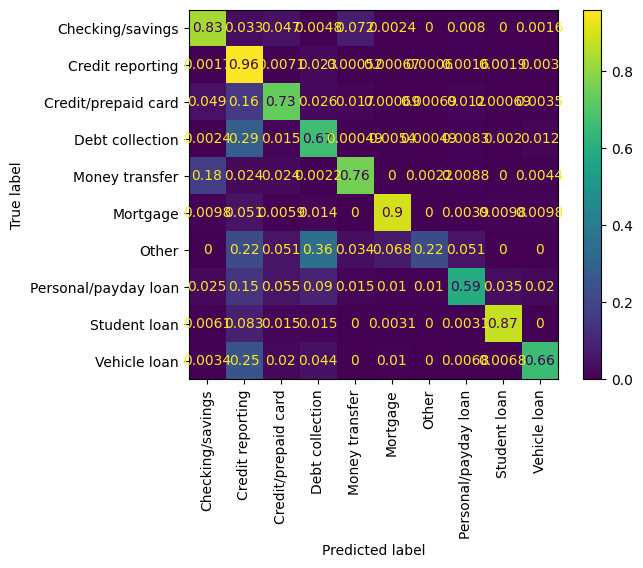

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y, adj, display_labels=names, xticks_rotation=90, normalize="true"
)

## Choose tau on validation

Same procedure as the baseline: sweep tau on the full validation set and fix the best value before touching test.

In [ ]:
from complaint.evaluation import tau_sweep

sweep = tau_sweep(val_out.predictions, y, log_ratio)
for tau, f1 in sweep.items():
    print(f"tau={tau:<5} val macro-F1={f1:.4f}")

BEST_TAU = max(sweep, key=sweep.get)
print(f"chosen tau: {BEST_TAU}")

## Test set

Run once, with `BEST_TAU` fixed on validation above. Predictions are saved next to the model so later analysis doesn't need the GPU.

In [ ]:
import numpy as np

test_out = trainer.predict(ds["test"])
y_test = test_out.label_ids
raw_test = test_out.predictions.argmax(-1)
adj_test = adjusted_preds(test_out.predictions, log_ratio, BEST_TAU)

print("test macro-F1 raw:          ", round(f1_score(y_test, raw_test, average="macro"), 4))
print(f"test macro-F1 tau={BEST_TAU}:", round(f1_score(y_test, adj_test, average="macro"), 4))
print(classification_report(y_test, adj_test, target_names=names, digits=3))

preds = dfs["test"].drop(columns=["labels"]).assign(
    pred_raw=[names[i] for i in raw_test],
    pred=[names[i] for i in adj_test],
)
preds.to_parquet(f"{cfg.output_dir}/preds_test.parquet", index=False)
np.save(f"{cfg.output_dir}/logits_test.npy", test_out.predictions)
print(f"saved predictions to {cfg.output_dir}")